# Семинар 6. Эмбеддинги, поиск по векторам и Grad-CAM

Семинар идёт сразу после лекции 6. На лекции было два сюжета — как обучать
пространство представлений и как посмотреть, что сеть выучила. Здесь мы оба
доводим до кода и, главное, **проверяем измерением** те утверждения, которые
на слайде можно было только объявить.

Работаем на настоящей задаче: **поиск похожей машины по фотографии**.
196 моделей, 8144 снимка, классы различаются с точностью до года выпуска —
«Audi S5 Coupe 2012» и «Audi S5 Convertible 2012» разные.

**Что сделаем:**

1. Соберём честную **open-set** задачу: обучаемся на одних моделях, а качество
   меряем на других, которых сеть никогда не видела.
2. Замерим два бейзлайна без обучения — **сырые пиксели** и **замороженный
   ImageNet** — и посмотрим глазами, что именно находит второй.
3. Напишем руками **contrastive loss** и наткнёмся на то, что margin
   нельзя выбирать без оглядки на геометрию.
4. Напишем **triplet loss** и сравним **случайные тройки, semi-hard
   и batch-hard** — почему выбор троек важнее выбора функции потерь.
5. Посмотрим на пространство эмбеддингов глазами и померим Recall@1 и mAP@R.
6. Построим **свой ANN-индекс** типа IVF по настоящим эмбеддингам машин
   и нарисуем кривую «recall против доли просмотренной базы».
7. Обучим сеть-**«умного Ганса»** на реальных фотографиях и поймаем её
   **Grad-CAM**, написанным с нуля на хуках.
8. Проверим сам метод на вменяемость: что он покажет на случайных весах.

**Как запускать.** Ноутбук работает и в Google Colab, и локально. Локально:

```
pip install torch torchvision scikit-learn matplotlib numpy pyarrow
```

Данные — 46 МБ; если папки `data/stanford-cars` рядом с ноутбуком нет
(так будет в Colab), ноутбук скачает их сам. Всё считается **на процессоре**;
полный прогон занимает около пяти минут, самая долгая часть — разовый расчёт
признаков ResNet18 для 8144 фотографий.

⚠️ **Материала здесь больше, чем на 90 минут.** Ядро, без которого семинар
теряет смысл, — разделы **1, 2, 4, 7** (open-set постановка, бейзлайны,
выбор троек, Grad-CAM). Раздел 3 (contrastive loss) короткий, но готовит
раздел 4. Раздел 6 (ANN-индекс) самостоятелен и легко переносится
на самостоятельное чтение. Раздел 8 (sanity check) занимает пять минут,
но он — самый важный вывод второй половины лекции; если выбирать между 6 и 8,
оставляйте 8.

In [1]:
import io
import time
import urllib.request
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from PIL import Image

torch.manual_seed(0)
np.random.seed(0)

# Считаем на CPU намеренно: модели маленькие, данные маленькие, а числа
# у всех получатся одинаковые.
device = "cpu"
print("PyTorch:", torch.__version__, "| torchvision:", torchvision.__version__)

PyTorch: 2.6.0+cu124 | torchvision: 0.21.0+cu124


---

## 1. Данные: модели машин, которых сеть не увидит

Главная мысль лекции — классификатор не годится там, где классы на применении
не те, что были на обучении. Чтобы это честно проверить, нужна задача, в которой
**тестовые классы не встречались при обучении вообще**.

Берём **Stanford Cars**: 196 моделей, 8144 фотографии, в среднем 41 на модель.
Класс здесь — конкретная модель конкретного года, а объект — её снимок
с улицы, из автосалона или из каталога. Это ровно постановка «класс = личность,
объект = снимок» из лекции, только вместо лиц машины.

* **модели 0–97** (`AM General Hummer` … `Ferrari FF`) — обучающая выборка;
* **модели 98–195** (`Ferrari California` … `smart fortwo`) — тестовая.
  Сеть их никогда не видела.

⚠️ Обратите внимание: выборка делится **по классам**, а не по фотографиям.
Если бы снимки одной модели попали и в обучение, и в тест, измеренное качество
не значило бы ничего — это та самая грабля со слайда 14 лекции.

In [2]:
DATA = Path("data/stanford-cars")
PARQUET_URL = ("https://huggingface.co/datasets/pkuHaowei/stanford-cars/"
               "resolve/main/data/train-00000-of-00001-500285c7b92025f4.parquet")
NAMES_URL = "https://huggingface.co/datasets/tanganke/stanford_cars/raw/main/README.md"
N_TRAIN_CLASSES = 98


def load_local():
    """Данные лежат рядом с ноутбуком — так их раздают на занятии."""
    names = {int(l.split("\t")[0]): l.split("\t")[1].strip()
             for l in (DATA / "classes.txt").read_text(encoding="utf8").splitlines()}
    files, labels = [], []
    for folder in sorted((DATA / "images").iterdir()):
        if not folder.is_dir():
            continue
        cls = int(folder.name.split("_")[0])
        for f in sorted(folder.glob("*.jpg")):
            files.append(f)
            labels.append(cls)
    X = np.zeros((len(files), 128, 128, 3), np.uint8)
    for i, f in enumerate(files):
        X[i] = np.asarray(Image.open(f).convert("RGB"))
    return X, np.array(labels), names


def load_remote():
    """Запасной путь (Colab): тянем зеркало датасета сами, 232 МБ."""
    import pyarrow.parquet as pq
    import yaml
    print("данных рядом нет — качаю зеркало (232 МБ), это займёт полминуты…")
    blob = urllib.request.urlopen(PARQUET_URL, timeout=600).read()
    tab = pq.read_table(io.BytesIO(blob))
    labels = np.array(tab.column("label").to_pylist())
    raw = tab.column("image").to_pylist()
    X = np.zeros((len(labels), 128, 128, 3), np.uint8)
    for i, d in enumerate(raw):
        im = Image.open(io.BytesIO(d["bytes"])).convert("RGB")
        X[i] = np.asarray(im if im.size == (128, 128) else im.resize((128, 128)))
    md = urllib.request.urlopen(NAMES_URL, timeout=120).read().decode("utf8")
    nm = yaml.safe_load(md.split("---")[1])["dataset_info"]["features"][1]
    names = {int(k): v for k, v in nm["dtype"]["class_label"]["names"].items()}
    return X, labels, names


t0 = time.time()
X, y_np, CLASS_NAMES = load_local() if (DATA / "classes.txt").exists() else load_remote()
y_all = torch.from_numpy(y_np)
print("загружено за %.0f с" % (time.time() - t0))

tr_mask, te_mask = y_all < N_TRAIN_CLASSES, y_all >= N_TRAIN_CLASSES
y_tr, y_te = y_all[tr_mask], y_all[te_mask]
X_te_img = X[te_mask.numpy()]        # понадобятся картинки тестовой половины

print("всего: %d фото, %d моделей" % (len(X), len(y_all.unique())))
print("обучение: %d фото, %d моделей" % (len(y_tr), len(y_tr.unique())))
print("тест:     %d фото, %d моделей" % (len(y_te), len(y_te.unique())))
print("пересечение классов:", set(y_tr.tolist()) & set(y_te.tolist()), "— пусто, как и задумано")

загружено за 5 с
всего: 8144 фото, 196 моделей
обучение: 4052 фото, 98 моделей
тест:     4092 фото, 98 моделей
пересечение классов: set() — пусто, как и задумано


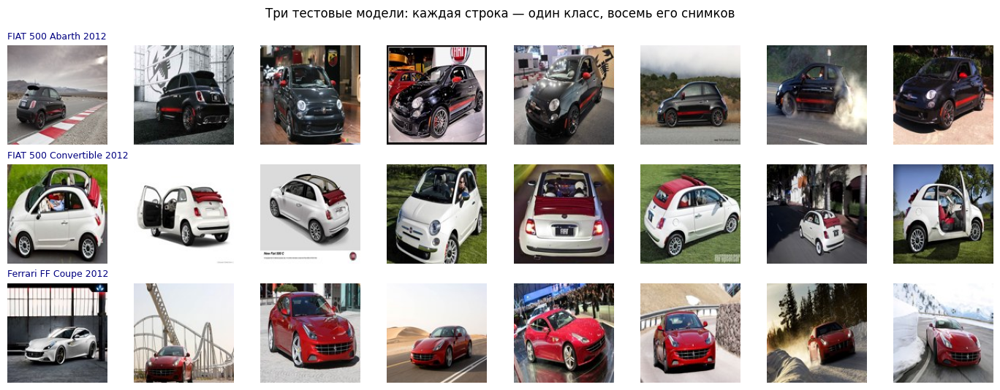

In [3]:
fig, axes = plt.subplots(3, 8, figsize=(14, 5.4))
for row, cls in enumerate(sorted(y_te.unique().tolist())[:3]):
    idx = np.where(y_np == cls)[0][:8]
    for j, i in enumerate(idx):
        axes[row, j].imshow(X[i])
        axes[row, j].axis("off")
    axes[row, 0].set_title(CLASS_NAMES[cls], fontsize=9, loc="left", color="navy")
fig.suptitle("Три тестовые модели: каждая строка — один класс, восемь его снимков",
             fontsize=12)
fig.tight_layout()
plt.show()

Посмотрите на строки внимательно. Внутри одного класса меняется **всё**: цвет
кузова, ракурс, фон, освещение. А между соседними классами разница бывает
в форме бампера. Именно поэтому задача называется fine-grained и именно
поэтому она честная: «похоже» и «то же самое» здесь разные вещи.

Теперь напишем **метрику**, которой будем пользоваться до конца первой половины.

`recall_at_1` берёт эмбеддинги тестовых объектов, для каждого ищет ближайшего
соседа **среди остальных** (сам объект исключается — иначе метрика всегда 1)
и считает долю случаев, когда класс соседа совпал.

Расстояние считаем по косинусу на L2-нормированных векторах: как разбирали
на лекции (слайд 7), после нормировки порядок соседей по косинусу и по евклиду
одинаковый, а матричное умножение считается одной строкой.

In [4]:
def recall_at_1(Z, y):
    """Доля объектов, у которых ближайший сосед — того же класса."""
    S = Z @ Z.T
    S.fill_diagonal_(-2.0)              # сам себе не сосед
    return (y[S.argmax(dim=1)] == y).float().mean().item()


def mean_ap(Z, y):
    """mAP@R: учитывает не только первого соседа, но весь список своих."""
    S = Z @ Z.T
    S.fill_diagonal_(-2.0)
    order = S.argsort(dim=1, descending=True)
    aps = []
    for i in range(len(y)):
        R = int((y == y[i]).sum().item()) - 1
        if R == 0:
            continue
        hits = (y[order[i, :R]] == y[i]).float()
        prec = hits.cumsum(0) / torch.arange(1, R + 1, dtype=torch.float)
        aps.append((prec * hits).sum().item() / R)
    return float(np.mean(aps))


def pairwise_dist(Z):
    """Матрица евклидовых расстояний между L2-нормированными векторами.

    Пользуемся тождеством со слайда 7: ‖a − b‖² = 2 − 2·cos(a, b).
    ⚠️ Отсюда же важное следствие: на единичной сфере расстояние не может
    превысить 2. Это пригодится в разделе 3.
    """
    sim = Z @ Z.T
    return (2.0 - 2.0 * sim).clamp(min=1e-12).sqrt()

---

## 2. Два бейзлайна без единого шага обучения

Прежде чем что-то обучать, надо понять, с чем сравнивать:

1. **сырые пиксели** — картинка, вытянутая в вектор. Самый честный «нулевой»
   вариант: никакого обучения вообще;
2. **случайная свёрточная сеть** — ResNet18 с необученными весами. Показывает,
   сколько даёт сама архитектура;
3. **замороженный ImageNet** — ResNet18, обученный на ImageNet, без последнего
   слоя. Никакого дообучения под машины: просто берём вектор длины 512.

Третий пункт — это transfer learning из лекции 3 в его самой дешёвой форме,
и в индустрии именно он является правильной точкой отсчёта. Обучать что-то,
не проверив его, — распространённая ошибка.

In [5]:
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)


def as_tensor(batch_uint8):
    """uint8 HWC → нормированный float CHW.

    ⚠️ Держим данные в uint8 и конвертируем по батчам: все 8144 фото
    во float32 заняли бы 1,6 ГБ.
    """
    t = torch.from_numpy(batch_uint8).permute(0, 3, 1, 2).float() / 255.
    return (t - IMAGENET_MEAN) / IMAGENET_STD


def extract(model, X_uint8, batch=128):
    model.eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(X_uint8), batch):
            out.append(model(as_tensor(X_uint8[i:i + batch])))
    return torch.cat(out)


def backbone(pretrained=True, seed=0):
    """ResNet18 без классифицирующего слоя: картинка → вектор 512."""
    torch.manual_seed(seed)
    w = torchvision.models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
    net = torchvision.models.resnet18(weights=w)
    return nn.Sequential(*list(net.children())[:-1], nn.Flatten())


t0 = time.time()
FEATS = extract(backbone(pretrained=True), X)
print("признаки ImageNet для %d фото посчитаны за %.0f с" % (len(X), time.time() - t0))
print("размерность:", tuple(FEATS.shape))

признаки ImageNet для 8144 фото посчитаны за 62 с
размерность: (8144, 512)


In [6]:
Z_pix = F.normalize(torch.from_numpy(X_te_img).float().flatten(1) / 255., dim=1)
Z_rand = F.normalize(extract(backbone(pretrained=False), X_te_img), dim=1)
Z_frozen = F.normalize(FEATS[te_mask], dim=1)

print("%-26s %10s %10s" % ("бейзлайн", "Recall@1", "mAP@R"))
for name, Z in (("сырые пиксели", Z_pix), ("случайная ResNet18", Z_rand),
                ("замороженный ImageNet", Z_frozen)):
    print("%-26s %10.3f %10.3f" % (name, recall_at_1(Z, y_te), mean_ap(Z, y_te)))
print()
print("случайное угадывание дало бы примерно %.4f" % (1 / len(y_te.unique())))

бейзлайн                     Recall@1      mAP@R


сырые пиксели                   0.039      0.003


случайная ResNet18              0.042      0.003


замороженный ImageNet           0.195      0.023

случайное угадывание дало бы примерно 0.0102


Сырые пиксели фактически не работают — и это правильный результат, которого
не было бы на игрушечных данных. Ближайший сосед по пикселям — это «фотография
с похожим распределением яркости»: тот же фон, та же засветка, тот же ракурс.
К модели машины это отношения не имеет.

⚠️ Обратите внимание и на вторую строку: **случайная ResNet18 не лучше сырых
пикселей**. Архитектура сама по себе не даёт ничего — всё, что мы дальше
получим, будет результатом обучения, а не удачной формы сети.

Замороженный ImageNet — впятеро лучше, и это при том, что **под машины
его никто не настраивал**. Посмотрим, что именно он находит.

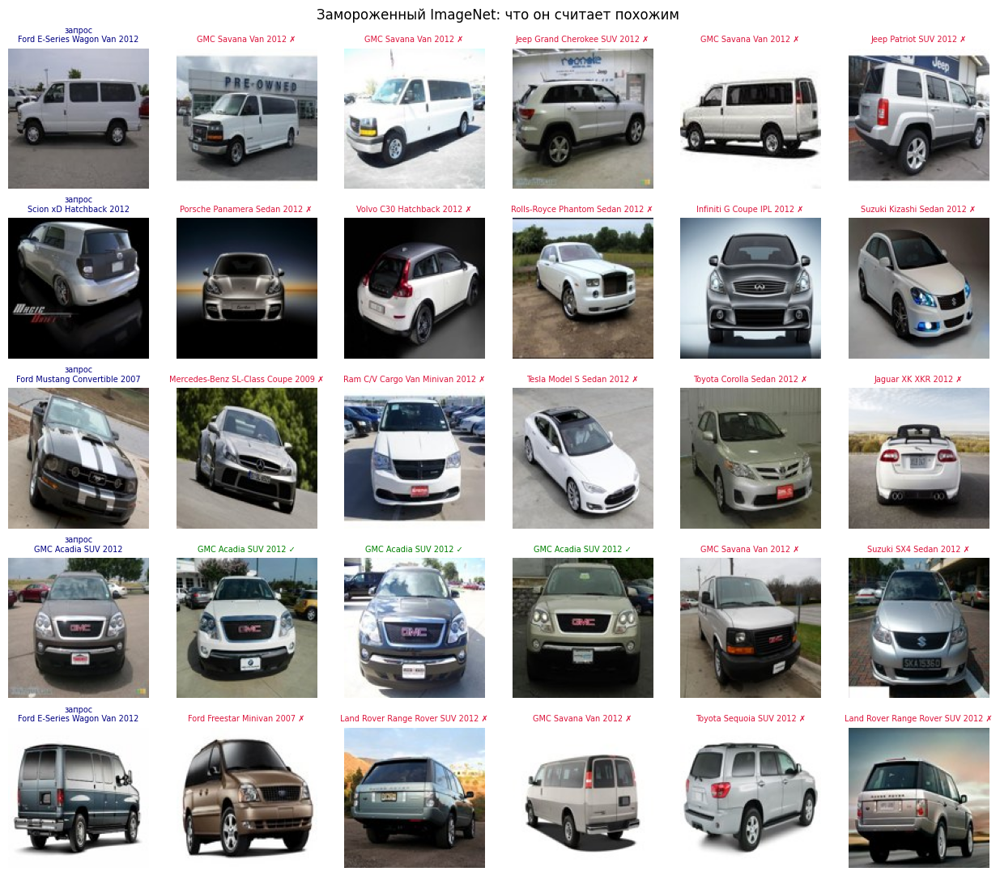

In [7]:
def show_neighbours(Z, title, n_queries=5, k=5, seed=3):
    S = Z @ Z.T
    S.fill_diagonal_(-2.0)
    rng = np.random.default_rng(seed)
    qs = rng.choice(len(y_te), n_queries, replace=False)
    fig, axes = plt.subplots(n_queries, k + 1, figsize=(2.1 * (k + 1), 2.2 * n_queries))
    for r, q in enumerate(qs):
        axes[r, 0].imshow(X_te_img[q])
        axes[r, 0].set_title("запрос\n%s" % CLASS_NAMES[int(y_te[q])],
                             fontsize=7, color="navy")
        for c, i in enumerate(S[q].argsort(descending=True)[:k].tolist()):
            hit = int(y_te[i]) == int(y_te[q])
            axes[r, c + 1].imshow(X_te_img[i])
            axes[r, c + 1].set_title("%s %s" % (CLASS_NAMES[int(y_te[i])],
                                                "✓" if hit else "✗"),
                                     fontsize=7, color="green" if hit else "crimson")
    for a in axes.ravel():
        a.axis("off")
    fig.suptitle(title, fontsize=12)
    fig.tight_layout()
    plt.show()


show_neighbours(Z_frozen, "Замороженный ImageNet: что он считает похожим")

⚠️ **Вот это — главная картинка первой половины семинара.** Посмотрите, что
происходит: соседи почти всегда осмысленные. Они того же **цвета**, сняты
с того же **ракурса** и часто того же **типа кузова**, что и запрос: на белый
фургон находятся белые фургоны и белые внедорожники, на серебристую машину —
серебристые. Человек сказал бы, что поиск работает.

Но крестиков намного больше, чем галочек. Замороженные признаки ImageNet
кластеризуют машины по **цвету, типу кузова и ракурсу** — по тому, что
различает классы ImageNet. А наш класс — конкретная модель, и он требует
различать то, что ImageNet просили игнорировать.

Именно этот зазор и закрывает метрическое обучение: «похоже глазами»
превратить в «то же самое». Займёмся этим.

---

## 3. Contrastive loss своими руками

Формула со слайда 10:

$$L = y \cdot d^2 + (1 - y)\cdot \max(0,\; m - d)^2$$

где `y = 1` для пары объектов одного класса, `y = 0` для разных,
`d` — евклидово расстояние между L2-нормированными векторами.

**Что именно обучаем.** Бэкбон оставляем замороженным, а поверх его признаков
учим один линейный слой 512 → 512. Так делают, когда данных мало: это
дообучение из лекции 3 в режиме «feature extraction». Заодно это делает
семинар быстрым — признаки посчитаны один раз, и каждая следующая
конфигурация обучается за секунды, а не за минуты.

⚠️ Слой инициализируем **тождественной матрицей**. Тогда до обучения голова
не портит признаки, и любое изменение Recall@1 — это результат обучения,
а не случайной проекции.

In [8]:
FEAT_MU = FEATS[tr_mask].mean(0)
FEAT_SD = FEATS[tr_mask].std(0) + 1e-6
H_tr = (FEATS[tr_mask] - FEAT_MU) / FEAT_SD
H_te = (FEATS[te_mask] - FEAT_MU) / FEAT_SD


def make_head(seed=0, dim=512):
    torch.manual_seed(seed)
    h = nn.Linear(512, dim)
    nn.init.eye_(h.weight)          # старт = «ничего не делать»
    nn.init.zeros_(h.bias)
    return h


def pk_batches(y, P=16, K=4, seed=0, n_batches=60):
    """P классов по K снимков: в батче гарантированно есть из чего выбирать.

    ⚠️ Сид зависит от номера эпохи: с фиксированным сидом все эпохи видели бы
    один и тот же порядок объектов.
    """
    rng = np.random.default_rng(seed)
    by_class = {c: np.where(y.numpy() == c)[0] for c in np.unique(y.numpy())}
    classes = np.array(list(by_class))
    for _ in range(n_batches):
        sel = rng.choice(classes, P, replace=False)
        yield torch.from_numpy(np.concatenate(
            [rng.choice(by_class[c], K, replace=len(by_class[c]) < K) for c in sel]))


def train_head(loss_fn, epochs=30, lr=1e-4, seed=0, track=None):
    """Общий цикл: меняется только функция потерь.

    loss_fn(Z, y, epoch) -> скаляр; track(Z, y, epoch) -> число для истории.
    """
    head = make_head(seed)
    opt = torch.optim.Adam(head.parameters(), lr=lr)
    hist = []
    for ep in range(epochs):
        vals, n = 0.0, 0
        for idx in pk_batches(y_tr, seed=1000 * seed + ep):
            Z = F.normalize(head(H_tr[idx]), dim=1)
            loss = loss_fn(Z, y_tr[idx], ep)
            if track is not None:
                vals += track(Z.detach(), y_tr[idx], ep)
                n += 1
            opt.zero_grad()
            loss.backward()
            opt.step()
        if track is not None:
            hist.append(vals / max(n, 1))
    with torch.no_grad():
        return F.normalize(head(H_te), dim=1), hist

In [9]:
def contrastive_loss(Z, y, margin=1.0):
    D = pairwise_dist(Z)
    same = (y[:, None] == y[None, :]).float()
    iu = torch.triu(torch.ones_like(same), diagonal=1).bool()   # каждая пара один раз
    d, s = D[iu], same[iu]
    pos = s * d.pow(2)
    neg = (1 - s) * F.relu(margin - d).pow(2)
    return (pos + neg).mean()


# проверим формулу там, где ответ считается в уме
z = F.normalize(torch.tensor([[1.0, 0.0], [1.0, 0.0], [0.0, 1.0]]), dim=1)
lbl = torch.tensor([0, 0, 1])
D = pairwise_dist(z)
print("d(свои)  = %.3f  (векторы совпадают)" % D[0, 1])
print("d(чужие) = %.3f  (перпендикулярны, значит √2)" % D[0, 2])
print("contrastive loss при m = 1: %.4f" % contrastive_loss(z, lbl).item())
print("  чужие дальше m = 1 → штрафа нет; свои совпали → штрафа нет. Итого 0.")

d(свои)  = 0.000  (векторы совпадают)
d(чужие) = 1.414  (перпендикулярны, значит √2)
contrastive loss при m = 1: 0.0000
  чужие дальше m = 1 → штрафа нет; свои совпали → штрафа нет. Итого 0.


In [10]:
r_frozen = recall_at_1(Z_frozen, y_te)

t0 = time.time()
Z_contr1, _ = train_head(lambda Z, y, ep: contrastive_loss(Z, y, margin=1.0))
print("обучено за %.0f с" % (time.time() - t0))
print("contrastive, m = 1.0:   Recall@1 = %.3f" % recall_at_1(Z_contr1, y_te))
print("замороженный ImageNet:  Recall@1 = %.3f" % r_frozen)
print()
print("⚠️ разница %+.3f — обучение сделало ХУЖЕ, чем не обучать вовсе."
      % (recall_at_1(Z_contr1, y_te) - r_frozen))

обучено за 8 с
contrastive, m = 1.0:   Recall@1 = 0.167
замороженный ImageNet:  Recall@1 = 0.195

⚠️ разница -0.028 — обучение сделало ХУЖЕ, чем не обучать вовсе.


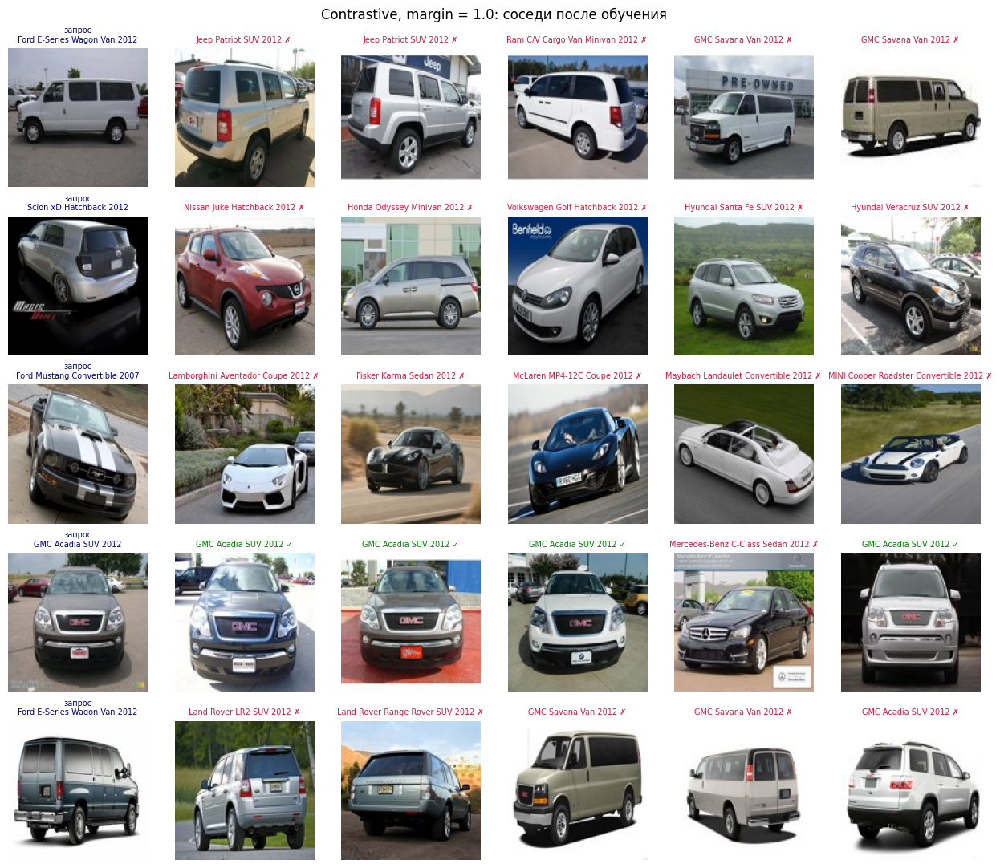

In [11]:
# Те же пять запросов, что у замороженного ImageNet: seed фиксирует их выбор.
show_neighbours(Z_contr1, "Contrastive, margin = 1.0: соседи после обучения", seed=3)

### Почему обучение ухудшило результат

Учебниковое значение `m = 1` пришло из работы Hadsell et al. (2006), где
эмбеддинги **не нормировали**: расстояние там могло быть любым, и единица была
просто масштабом.

У нас векторы лежат на единичной сфере, а там, как мы посчитали выше,
$d = \sqrt{2 - 2\cos}$ и **максимально возможное расстояние равно 2**
(у противоположных векторов). Требование «чужие дальше 1» на сфере означает
«чужие дальше 60°» — то есть изрядная часть сферы объявляется достаточно
далёкой, отталкивать чужих функция почти перестаёт, зато честно стягивает
своих. Пространство схлопывается.

Посмотрим на это прямо: переберём margin.

In [12]:
t0 = time.time()
grid = {}
for m in (0.5, 1.0, 1.4, 2.0):
    Z, _ = train_head(lambda Z, y, ep, mm=m: contrastive_loss(Z, y, margin=mm))
    grid[m] = (recall_at_1(Z, y_te), Z)
print("перебор занял %.0f с\n" % (time.time() - t0))

print("%-10s %10s %18s" % ("margin", "Recall@1", "против заморозки"))
for m in sorted(grid):
    print("%-10.1f %10.3f %+17.3f" % (m, grid[m][0], grid[m][0] - r_frozen))
print()
print("максимально возможное расстояние на единичной сфере: %.3f" % 2.0)

best_m = max(grid, key=lambda k: grid[k][0])
Z_contr = grid[best_m][1]
print("лучший margin: %.1f" % best_m)

перебор занял 26 с

margin       Recall@1   против заморозки
0.5             0.137            -0.057
1.0             0.167            -0.028
1.4             0.227            +0.032
2.0             0.239            +0.045

максимально возможное расстояние на единичной сфере: 2.000
лучший margin: 2.0


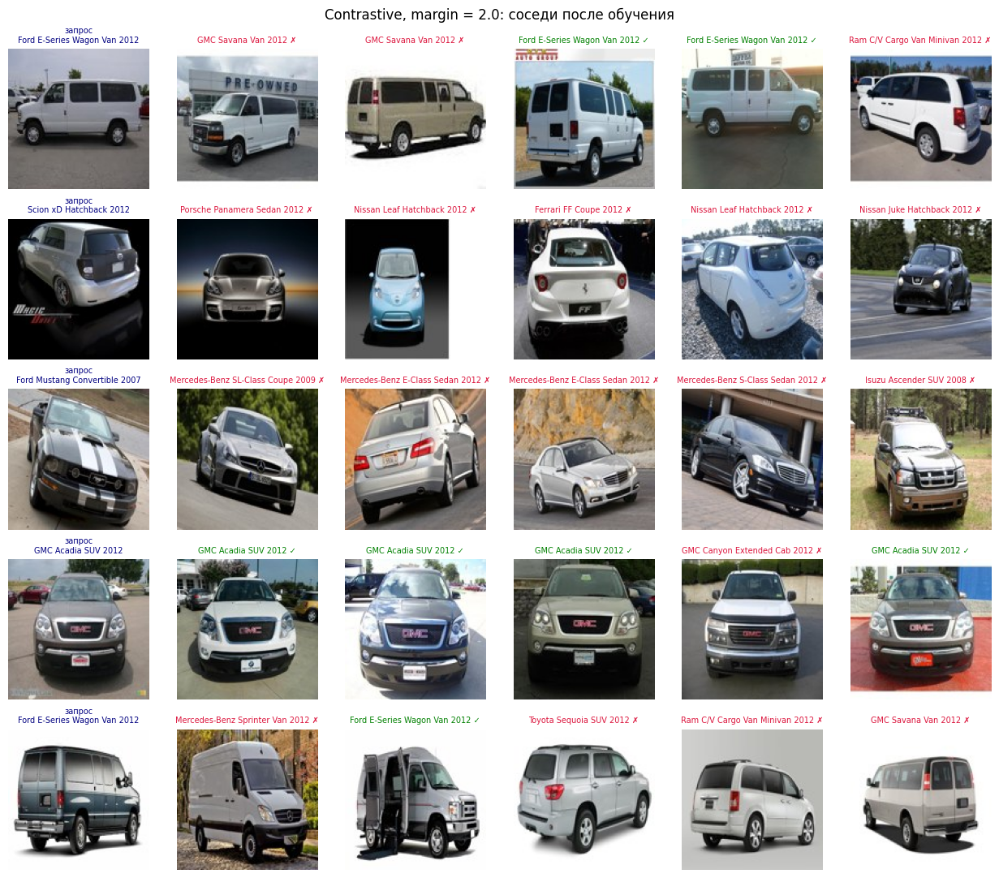

In [13]:
# Сравните с ImageNet и margin = 1: зелёные подписи — та же модель машины,
# красные — другая. Пять запросов иллюстрируют результат, но не заменяют Recall@1.
show_neighbours(Z_contr, "Contrastive, margin = %.1f: соседи после обучения" % best_m,
                seed=3)

Кривая монотонная: чем ближе margin к геометрическому пределу 2, тем лучше —
и только при margin, сравнимом с диаметром сферы, обучение начинает
переигрывать заморозку.

📌 **Что из этого забрать.** «Margin» — не абстрактное число: он живёт в тех же
единицах, что и расстояние, а диапазон расстояний задаётся тем, нормируете вы
эмбеддинги или нет. Перенося формулу из статьи, проверяйте не только формулу,
но и геометрию, в которой она записана.

**Задание 1.** Уберите L2-нормировку (обучайте и меряйте на ненормированных
векторах) и подберите margin заново. Какой порядок величины у него теперь?
Стало ли лучше, чем на сфере?

---

## 4. Triplet loss и выбор троек

Главное утверждение лекции про метрическое обучение (слайды 12–13):
**функция потерь простая, а вся сложность — в том, какие тройки ей скармливать.**
Проверим это напрямую.

Формула со слайда 11:

$$L = \max\big(0,\; d(a,p) - d(a,n) + m\big)$$

Требование **относительное**: чужой должен быть дальше своего на margin —
в отличие от contrastive, который задаёт абсолютный порог на весь датасет.

Три стратегии выбора троек:

* **random** — для каждого якоря случайный свой и случайный чужой;
* **semi-hard** — чужой дальше своего, но ближе, чем `d(a,p) + margin`
  (так делали в FaceNet);
* **batch-hard** — **самый далёкий свой** и **самый близкий чужой** в батче
  (Hermans et al., слайд 13).

### Сначала — правильный батч

Слайд 13 говорит: батч собирают **PK-сэмплером**. Это не косметика — посмотрите,
что даёт обычное случайное перемешивание при 98 классах.

In [14]:
def random_batches(n, size, seed):
    g = torch.Generator().manual_seed(seed)
    perm = torch.randperm(n, generator=g)
    for i in range(0, n - size + 1, size):
        yield perm[i:i + size]


for name, gen in (("случайный батч 64", random_batches(len(y_tr), 64, 0)),
                  ("PK-сэмплер 16×4", pk_batches(y_tr, seed=0))):
    idx = next(iter(gen))
    yy = y_tr[idx]
    same = yy[:, None] == yy[None, :]
    n_pos = (same.sum(1) - 1).float()
    print("%-20s классов в батче %2d, своих у якоря в среднем %.2f"
          % (name, len(set(yy.tolist())), n_pos.mean()))

случайный батч 64    классов в батче 50, своих у якоря в среднем 0.56
PK-сэмплер 16×4      классов в батче 16, своих у якоря в среднем 3.00


При случайном перемешивании у якоря почти нет своих на весь батч — выбирать
«самого далёкого своего» попросту не из чего, и batch-hard вырождается.
Дальше везде пользуемся PK-сэмплером.

In [15]:
def triplet_parts(Z, y, mining="random", seed=0):
    """Возвращает d(a,p), d(a,n) и маску якорей, для которых тройка существует."""
    D = pairwise_dist(Z)
    n = len(y)
    same = y[:, None] == y[None, :]
    eye = torch.eye(n, dtype=torch.bool)
    pos_mask, neg_mask = same & ~eye, ~same
    valid = pos_mask.any(1) & neg_mask.any(1)
    if mining == "hard":
        d_ap = (D * pos_mask).max(dim=1).values                     # самый далёкий свой
        d_an = (D + (~neg_mask).float() * 1e6).min(dim=1).values    # самый близкий чужой
    elif mining == "semi":
        d_ap = (D * pos_mask).max(dim=1).values
        ring = neg_mask & (D > d_ap[:, None])        # чужие дальше своего
        # среди них — самый близкий; если кольцо пусто, берём самого далёкого чужого
        d_an = torch.where(ring.any(1),
                           (D + (~ring).float() * 1e6).min(dim=1).values,
                           (D * neg_mask).max(dim=1).values)
    else:
        g = torch.Generator().manual_seed(seed)
        p_idx = torch.multinomial(pos_mask.float() + 1e-12, 1, generator=g).squeeze(1)
        n_idx = torch.multinomial(neg_mask.float() + 1e-12, 1, generator=g).squeeze(1)
        rows = torch.arange(n)
        d_ap, d_an = D[rows, p_idx], D[rows, n_idx]
    return d_ap, d_an, valid


def triplet_loss(Z, y, margin=0.2, mining="random", seed=0):
    d_ap, d_an, valid = triplet_parts(Z, y, mining, seed)
    if valid.sum() == 0:
        return Z.sum() * 0.0
    return F.relu(d_ap[valid] - d_an[valid] + margin).mean()


def frac_active(Z, y, margin=0.2, mining="random", seed=0):
    """Доля троек с НЕнулевым штрафом — то есть тех, что реально дают градиент."""
    d_ap, d_an, valid = triplet_parts(Z, y, mining, seed)
    if valid.sum() == 0:
        return 0.0
    return ((d_ap[valid] - d_an[valid] + margin) > 0).float().mean().item()

In [16]:
SEEDS = (0, 1, 2)

t0 = time.time()
trip, hist_active, trip_spread = {}, {}, {}
for mining in ("random", "semi", "hard"):
    vals = []
    for s in SEEDS:
        Z, hist = train_head(
            lambda Z, y, ep, mm=mining: triplet_loss(Z, y, mining=mm, seed=ep),
            seed=s,
            track=(lambda Z, y, ep, mm=mining: frac_active(Z, y, mining=mm, seed=ep))
            if s == 0 else None)
        vals.append(recall_at_1(Z, y_te))
        if s == 0:
            trip[mining] = Z              # для дальнейших разделов берём сид 0
            hist_active[mining] = hist
    trip_spread[mining] = (float(np.mean(vals)), float(np.std(vals)), vals)
print("девять голов (3 стратегии × %d сида) обучены за %.0f с\n"
      % (len(SEEDS), time.time() - t0))

print("⚠️ Одного прогона мало: сравниваем средние по %d сидам и смотрим на разброс.\n"
      % len(SEEDS))
print("%-26s %10s %10s %10s" % ("стратегия", "R@1 сид 0", "среднее", "разброс"))
for mining, label in (("random", "случайные тройки"), ("semi", "semi-hard"),
                      ("hard", "batch-hard")):
    mu, sd, vals = trip_spread[mining]
    print("%-26s %10.3f %10.3f %10.3f" % (label, vals[0], mu, sd))
print()

rows = [
    ("сырые пиксели",             Z_pix),
    ("случайная ResNet18",        Z_rand),
    ("замороженный ImageNet",     Z_frozen),
    ("contrastive (m = %.1f)" % best_m, Z_contr),
    ("triplet, случайные тройки", trip["random"]),
    ("triplet, semi-hard",        trip["semi"]),
    ("triplet, batch-hard",       trip["hard"]),
]
print("%-30s %10s %10s" % ("", "Recall@1", "mAP@R"))
for name, Z in rows:
    print("%-30s %10.3f %10.3f" % (name, recall_at_1(Z, y_te), mean_ap(Z, y_te)))
print()
print("все числа — на %d моделях, которых ни одна сеть не видела при обучении"
      % len(y_te.unique()))
print("(строки с тройками — сид 0; средние по трём сидам напечатаны выше)")

девять голов (3 стратегии × 3 сида) обучены за 62 с

⚠️ Одного прогона мало: сравниваем средние по 3 сидам и смотрим на разброс.

стратегия                   R@1 сид 0    среднее    разброс
случайные тройки                0.214      0.213      0.002
semi-hard                       0.219      0.220      0.001
batch-hard                      0.230      0.228      0.001

                                 Recall@1      mAP@R


сырые пиксели                       0.039      0.003


случайная ResNet18                  0.042      0.003


замороженный ImageNet               0.195      0.023


contrastive (m = 2.0)               0.239      0.035


triplet, случайные тройки           0.214      0.030


triplet, semi-hard                  0.219      0.033


triplet, batch-hard                 0.230      0.032

все числа — на 98 моделях, которых ни одна сеть не видела при обучении
(строки с тройками — сид 0; средние по трём сидам напечатаны выше)


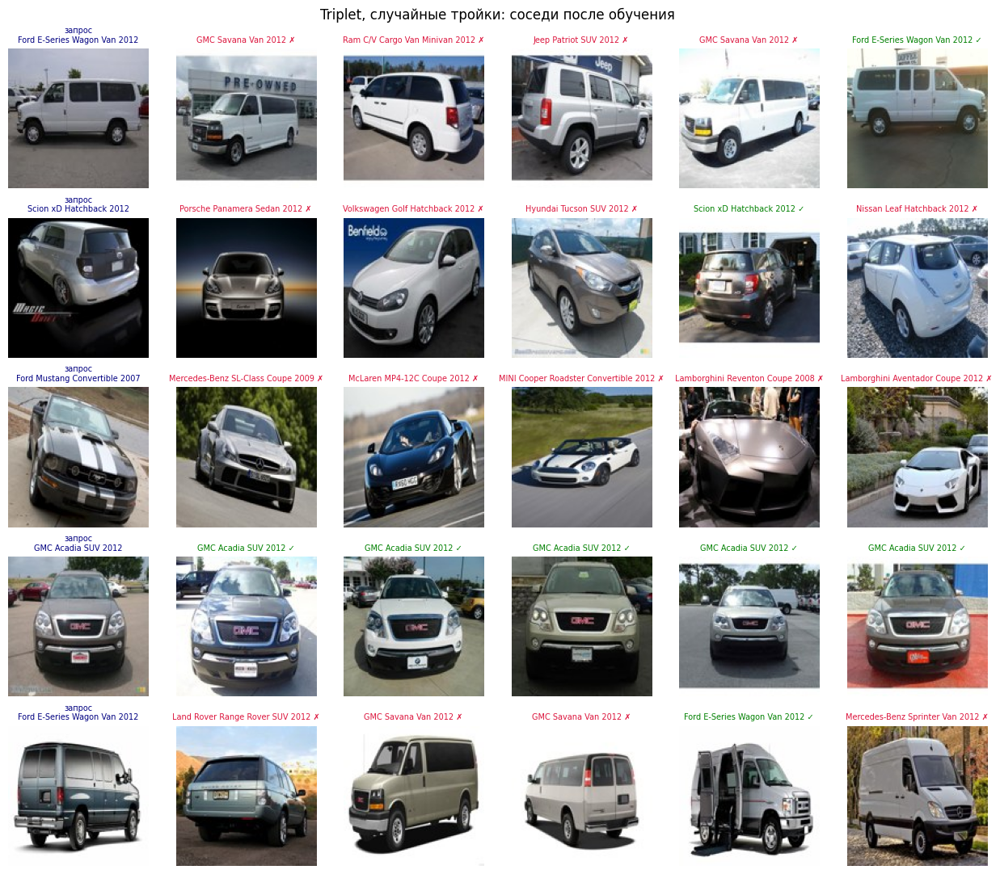

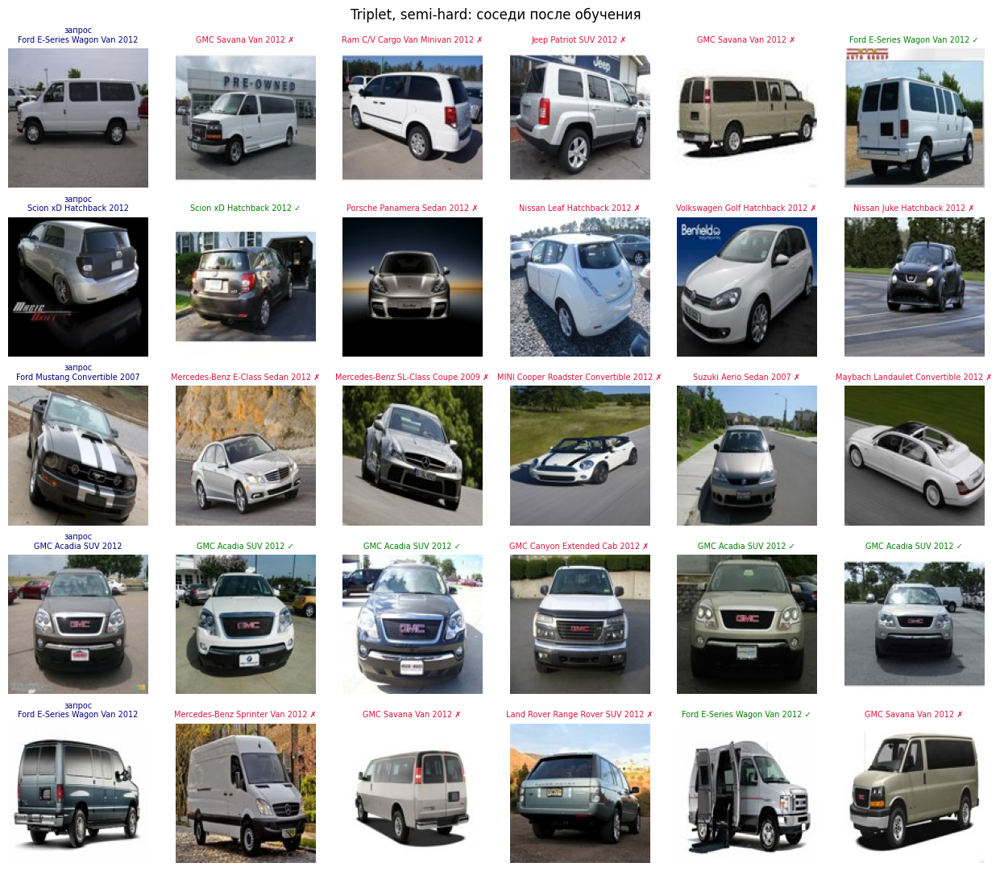

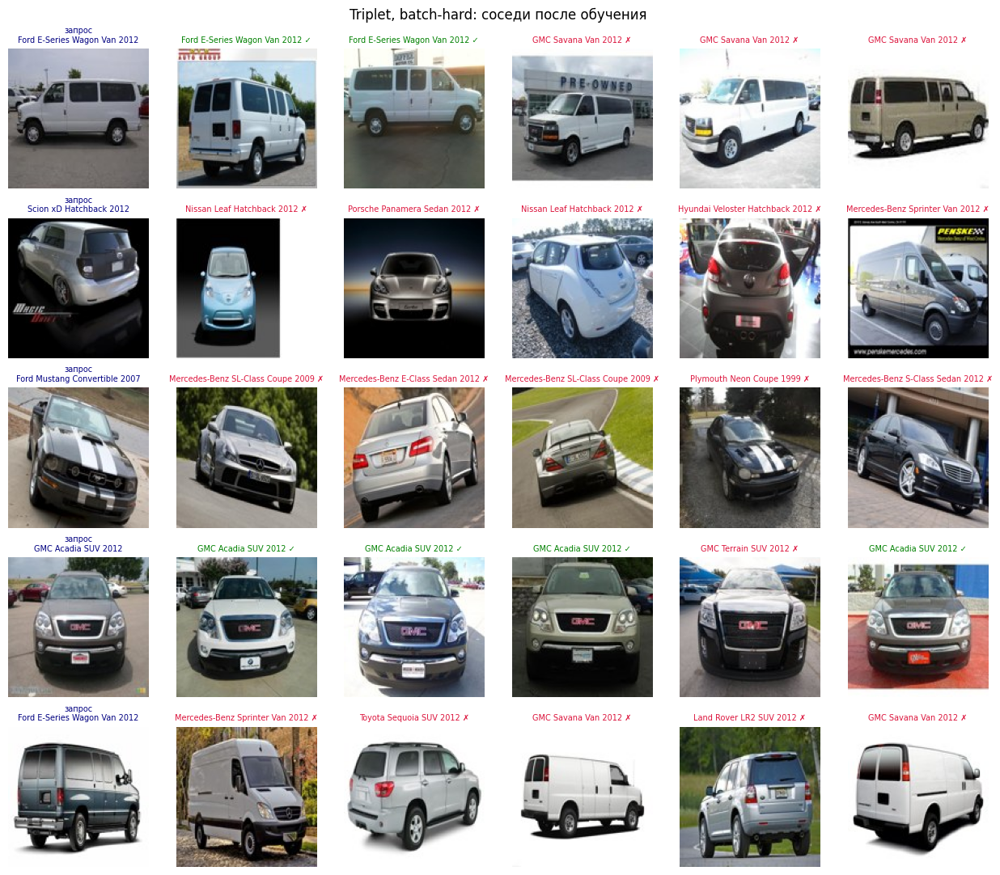

In [17]:
# Для всех стратегий берём модели с сидом обучения 0 и те же запросы.
# Здесь seed=3 выбирает фотографии для показа, а не задаёт обучение.
for mining, label in (("random", "случайные тройки"),
                      ("semi", "semi-hard"), ("hard", "batch-hard")):
    show_neighbours(trip[mining], "Triplet, %s: соседи после обучения" % label, seed=3)

Лесенка из лекции (слайд 12) воспроизвелась: **случайные тройки < semi-hard <
batch-hard** — при одинаковых сети, оптимизаторе и числе эпох. Меняется только
то, какие тройки попадают в формулу.

⚠️ **Но посмотрите на колонку «сид 0» рядом с колонкой «среднее».** В одиночном
прогоне semi-hard и случайные тройки различаются на пару тысячных — меньше
собственного разброса метода, то есть по одному прогону вывод «semi-hard лучше»
сделать нельзя. Он держится только на усреднении по сидам, где разрыв
оказывается вчетверо больше шума. Разрыв же «случайные → batch-hard» виден
и на одном прогоне.

📌 Это общее правило, а не частность нашего датасета: **разницу меньше разброса
по сидам нельзя объявлять эффектом.** Большая часть противоречивых сравнений
в статьях по метрическому обучению — ровно этой природы.

Посмотрим, откуда берётся разница, — на **долю активных троек** по эпохам:
сколько троек в батче дают ненулевой штраф, то есть хоть чему-то учат.

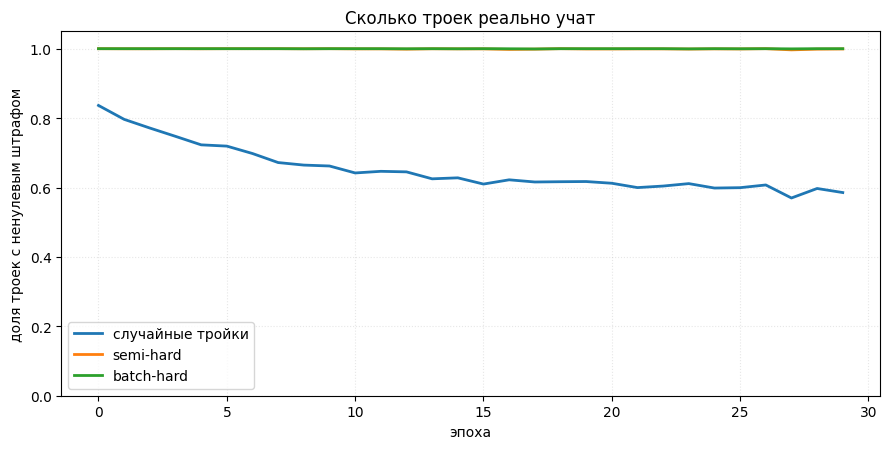

доля активных троек, эпоха 1 → эпоха 30:
  случайные    0.836 → 0.585
  semi-hard    1.000 → 0.999
  batch-hard   1.000 → 1.000


In [18]:
fig, ax = plt.subplots(figsize=(9, 4.6))
for mining, label in (("random", "случайные тройки"), ("semi", "semi-hard"),
                      ("hard", "batch-hard")):
    ax.plot(hist_active[mining], lw=2, label=label)
ax.set_xlabel("эпоха"); ax.set_ylabel("доля троек с ненулевым штрафом")
ax.set_ylim(0, 1.05); ax.legend(); ax.grid(alpha=0.3, ls=":")
ax.set_title("Сколько троек реально учат")
fig.tight_layout()
plt.show()

print("доля активных троек, эпоха 1 → эпоха %d:" % len(hist_active["random"]))
for mining, label in (("random", "случайные"), ("semi", "semi-hard"),
                      ("hard", "batch-hard")):
    h = hist_active[mining]
    print("  %-12s %.3f → %.3f" % (label, h[0], h[-1]))

Вот и объяснение. При случайном выборе доля работающих троек **падает по ходу
обучения**: чем лучше сеть, тем чаще случайный чужой и так дальше своего,
штраф нулевой, градиент нулевой, а вычислять тройку всё равно приходится.
К последней эпохе вхолостую уходит заметная часть батча. У batch-hard и
semi-hard активны практически все тройки все тридцать эпох: они всегда
находят в батче ту, которая ещё нарушает требование.

⚠️ Но обратите внимание: у semi-hard активных троек **ровно столько же**,
сколько у batch-hard, а качество всё-таки ниже. Значит, «много активных троек» —
условие необходимое, но не достаточное: важно ещё, **насколько трудны** эти
тройки, а не только то, что штраф у них ненулевой. Semi-hard сознательно
берёт не самого близкого чужого, а чужого из кольца — и платит за эту
осторожность.

### Побочное наблюдение: batch-hard почти не зависит от margin

В разделе 3 margin решал всё. Проверим, так ли это для троек.

In [19]:
t0 = time.time()
print("%-10s %18s %14s" % ("margin", "случайные тройки", "batch-hard"))
for m in (0.2, 0.5, 1.0, 1.5):
    Z_r, _ = train_head(lambda Z, y, ep, mm=m:
                        triplet_loss(Z, y, margin=mm, mining="random", seed=ep))
    Z_h, _ = train_head(lambda Z, y, ep, mm=m:
                        triplet_loss(Z, y, margin=mm, mining="hard", seed=ep))
    print("%-10.1f %18.3f %14.3f"
          % (m, recall_at_1(Z_r, y_te), recall_at_1(Z_h, y_te)))
print("\nперебор занял %.0f с" % (time.time() - t0))

margin       случайные тройки     batch-hard


0.2                     0.214          0.230


0.5                     0.175          0.230


1.0                     0.144          0.230


1.5                     0.138          0.230

перебор занял 52 с


Случайные тройки от margin разваливаются, batch-hard стоит как вкопанный.
Причина видна из предыдущего графика: при hard-майнинге почти каждая тройка
и так нарушает требование, поэтому margin меняет **величину** штрафа, но почти
не меняет **состав** троек, дающих градиент. А при случайном выборе margin —
единственное, что вообще определяет, попадёт ли тройка в обучение.

📌 То есть майнинг и margin — две ручки, крутящие одно и то же: какие тройки
дают градиент. Когда работает первая, вторая почти не нужна.

⚠️ **И честная оговорка про «triplet лучше contrastive».** Слайд 10 говорит,
что contrastive сегодня почти не применяют. На наших данных при **честно
подобранном** margin он даёт результат уровня batch-hard. Исторически лекция
права, но здесь видно, о чём работа Musgrave et al. «A Metric Learning Reality
Check» (слайд 40): при равных условиях разные функции потерь в метрическом
обучении расходятся куда меньше, чем принято думать, а бóльшую часть разницы
в статьях делают детали настройки.

**Задание 2.** Реализуйте **batch-all**: усреднить штраф по всем тройкам
батча с ненулевым штрафом (а не по одной на якорь). Где он окажется
относительно random и batch-hard и что произойдёт с долей активных троек?

---

## 5. Как выглядит пространство эмбеддингов

Посмотрим на тестовые классы глазами. Сжимаем 512 измерений до двух через PCA —
метод линейный и ничего не «дорисовывает», в отличие от t-SNE, который умеет
показать кластеры даже там, где их нет.

Чтобы картинка читалась, возьмём 8 тестовых моделей из 98.

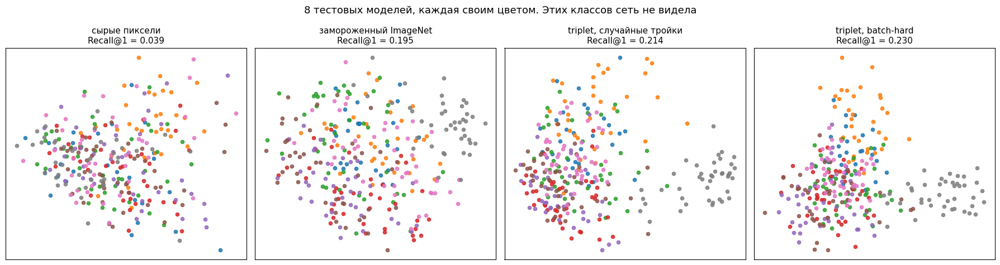

In [20]:
from sklearn.decomposition import PCA

show_classes = sorted(y_te.unique().tolist())[:8]
mask = torch.isin(y_te, torch.tensor(show_classes))

variants = [
    ("сырые пиксели", Z_pix),
    ("замороженный ImageNet", Z_frozen),
    ("triplet, случайные тройки", trip["random"]),
    ("triplet, batch-hard", trip["hard"]),
]

fig, axes = plt.subplots(1, 4, figsize=(18, 4.8))
for ax, (name, Z) in zip(axes, variants):
    P = PCA(n_components=2, random_state=0).fit_transform(Z[mask].numpy())
    ys = y_te[mask].numpy()
    for c in show_classes:
        m = ys == c
        ax.scatter(P[m, 0], P[m, 1], s=20, alpha=0.85)
    ax.set_title("%s\nRecall@1 = %.3f" % (name, recall_at_1(Z, y_te)), fontsize=11)
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("8 тестовых моделей, каждая своим цветом. Этих классов сеть не видела",
             fontsize=13)
fig.tight_layout()
plt.show()

⚠️ Не ждите здесь красиво разделённых кластеров: восемь моделей машин
в проекции на две главные компоненты из 512 не разойдутся, даже когда
Recall@1 растёт. Картинка честно показывает, насколько скромен выигрыш
в абсолютных числах, — а разница ловится метрикой, а не глазами. Это обычная
ситуация для fine-grained задач и хороший повод не принимать «визуализацию
эмбеддингов» за доказательство.

**Задание 3.** Посчитайте для каждого варианта отношение «среднее расстояние
между классами / среднее расстояние внутри класса» — ту величину, которая была
подписана под картинкой на слайде 6. Совпадает ли порядок вариантов по этому
отношению с порядком по Recall@1?

⚠️ Подсказка: **не совпадает**, и это главное в задании. Посмотрите
в таблице ниже на строку batch-hard: у него **худшее отношение** из всех
обученных вариантов и при этом лучший Recall@1 среди троек. Отношение средних
расстояний ничего не говорит о том, перепутаны ли ближайшие соседи; именно
поэтому качество меряют Recall@1, а не разбросом.

In [21]:
def spread_ratio(Z, y):
    D = pairwise_dist(Z)
    same = y[:, None] == y[None, :]
    eye = torch.eye(len(y), dtype=torch.bool)
    within = D[same & ~eye].mean().item()
    between = D[~same].mean().item()
    return within, between, between / max(within, 1e-9)


print("%-30s %8s %8s %8s %8s" % ("", "внутри", "между", "отнош.", "R@1"))
for name, Z in rows:
    w, b, r = spread_ratio(Z, y_te)
    print("%-30s %8.3f %8.3f %8.3f %8.3f" % (name, w, b, r, recall_at_1(Z, y_te)))

                                 внутри    между   отнош.      R@1


сырые пиксели                     0.685    0.694    1.014    0.039


случайная ResNet18                0.143    0.145    1.017    0.042


замороженный ImageNet             0.776    0.825    1.064    0.195


contrastive (m = 2.0)             1.331    1.410    1.059    0.239


triplet, случайные тройки         1.246    1.403    1.126    0.214


triplet, semi-hard                1.268    1.405    1.108    0.219


triplet, batch-hard               1.364    1.411    1.035    0.230


---

## 6. Поиск по векторам: свой ANN-индекс

Эмбеддинги посчитаны — теперь по ним надо искать. На лекции (слайды 25–27)
мы говорили, что полный перебор линеен по размеру базы и на больших базах
перестаёт помещаться в бюджет запроса. Построим **свой индекс типа IVF** —
тот самый, что был нарисован на слайде 25 — прямо по эмбеддингам машин.

FAISS ставить не будем: весь IVF — это k-means плюс два `argsort`, и написать
его самому куда полезнее, чем вызвать чужую функцию.

⚠️ База у нас маленькая (несколько тысяч векторов), и на ней полный перебор
и так мгновенный. Поэтому смотрим **не на секунды**, а на долю базы, которую
пришлось просмотреть ради нужного recall: именно это число переносится
на базы, где перебор в бюджет уже не влезает.

In [22]:
base = trip["hard"].numpy().astype(np.float32)      # настоящие эмбеддинги машин
NQ, K = 300, 10

rng = np.random.default_rng(0)
q_idx = rng.choice(len(base), NQ, replace=False)
queries = base[q_idx]

t0 = time.time()
sims_full = queries @ base.T
sims_full[np.arange(NQ), q_idx] = -2.0              # сам себе не сосед
truth = np.argsort(-sims_full, axis=1)[:, :K]
t_brute = time.time() - t0
print("база: %d векторов размерности %d" % (len(base), base.shape[1]))
print("полный перебор для %d запросов: %.3f с (%.3f мс на запрос)"
      % (NQ, t_brute, 1000 * t_brute / NQ))
print("память под базу: %.1f МБ" % (base.nbytes / 1024 ** 2))

база: 4092 векторов размерности 512
полный перебор для 300 запросов: 0.108 с (0.360 мс на запрос)
память под базу: 8.0 МБ


In [23]:
from sklearn.cluster import KMeans

NLIST = 100
t0 = time.time()
km = KMeans(n_clusters=NLIST, n_init=3, random_state=0).fit(base)
print("индекс построен за %.1f с" % (time.time() - t0))

labels = km.labels_
buckets = [np.where(labels == c)[0] for c in range(NLIST)]
cent = km.cluster_centers_ / np.linalg.norm(km.cluster_centers_, axis=1, keepdims=True)
cell_order = np.argsort(-(queries @ cent.T), axis=1)

print("размер ячейки: от %d до %d векторов (в среднем %.0f)"
      % (min(map(len, buckets)), max(map(len, buckets)), len(base) / NLIST))


def ivf_search(qi, nprobe, k=K):
    """Поиск по индексу: смотрим только nprobe ближайших ячеек."""
    cand = np.concatenate([buckets[c] for c in cell_order[qi, :nprobe]])
    cand = cand[cand != q_idx[qi]]
    if len(cand) == 0:
        return np.array([], dtype=int), 0
    sims = base[cand] @ queries[qi]
    return cand[np.argsort(-sims)[:k]], len(cand)

индекс построен за 2.1 с
размер ячейки: от 18 до 85 векторов (в среднем 41)


In [24]:
probes = [1, 2, 3, 5, 8, 12, 20, 30, 50, 100]
rec, frac = [], []
for npr in probes:
    hits, scanned = 0, 0
    for i in range(NQ):
        top, m = ivf_search(i, npr)
        scanned += m
        hits += len(set(top.tolist()) & set(truth[i].tolist()))
    rec.append(hits / (NQ * K))
    frac.append(scanned / (NQ * len(base)))

print("%8s %10s %14s %12s" % ("nprobe", "recall@10", "просмотрено", "ускорение"))
for npr, r, f in zip(probes, rec, frac):
    print("%8d %10.3f %13.2f %% %11.0f×" % (npr, r, 100 * f, 1 / max(f, 1e-9)))

  nprobe  recall@10    просмотрено    ускорение
       1      0.239          1.06 %          94×
       2      0.372          2.17 %          46×
       3      0.447          3.25 %          31×
       5      0.556          5.35 %          19×
       8      0.650          8.49 %          12×
      12      0.730         12.58 %           8×
      20      0.827         20.71 %           5×
      30      0.900         30.59 %           3×
      50      0.960         49.76 %           2×
     100      1.000         99.98 %           1×


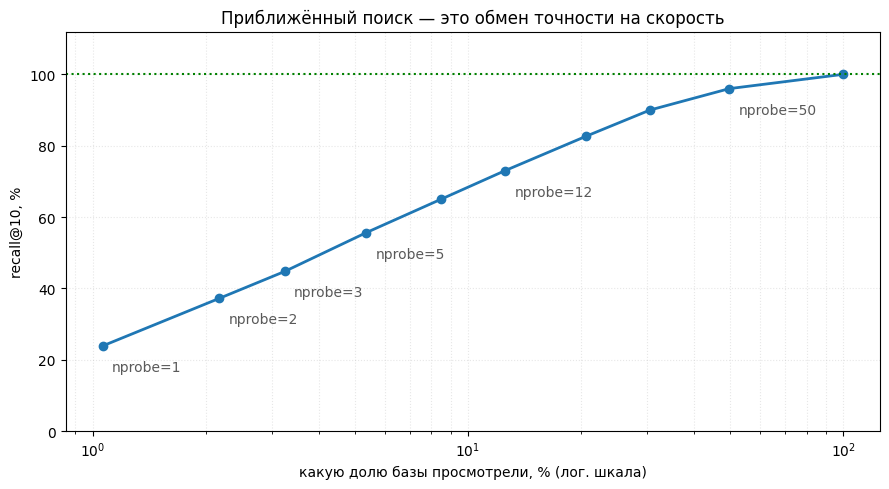

recall@10 ≥ 90 % достигается при nprobe = 30: просмотрено 30.6 % базы, то есть работы меньше в 3 раза


In [25]:
rec, frac = np.array(rec), np.array(frac)
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(frac * 100, rec * 100, marker="o", lw=2)
for npr, f, r in zip(probes, frac, rec):
    if npr in (1, 2, 3, 5, 12, 50):
        ax.annotate("nprobe=%d" % npr, (f * 100, r * 100),
                    xytext=(f * 100 * 1.06, r * 100 - 7), fontsize=10, color="0.35")
ax.axhline(100, ls=":", color="green")
ax.set_xscale("log")
ax.set_xlabel("какую долю базы просмотрели, % (лог. шкала)")
ax.set_ylabel("recall@10, %")
ax.set_ylim(0, 112)
ax.grid(alpha=0.3, ls=":", which="both")
ax.set_title("Приближённый поиск — это обмен точности на скорость")
fig.tight_layout()
plt.show()

def times_word(n):
    """«в 2 раза», но «в 5 раз» — согласование числительного."""
    n = int(round(n))
    if n % 100 in (11, 12, 13, 14):
        return "раз"
    return {1: "раз", 2: "раза", 3: "раза", 4: "раза"}.get(n % 10, "раз")


if (rec >= 0.90).any():
    i90 = int(np.argmax(rec >= 0.90))
    speedup = 1 / frac[i90]
    print("recall@10 ≥ 90 %% достигается при nprobe = %d: просмотрено %.1f %% базы, "
          "то есть работы меньше в %.0f %s"
          % (probes[i90], 100 * frac[i90], speedup, times_word(speedup)))
else:
    print("recall@10 не дошёл до 90 %% — база слишком мала для такого числа ячеек")

### ⚠️ Почему в лекции кривая была красивее

На слайде 26 приведено: recall@10 = 98 % при просмотре 2,7 % базы, ускорение
почти в сорок раз. У нас при тех же ≈3 % базы recall@10 вдвое с лишним ниже.
Разница не в коде — код тот же самый. Проверим гипотезу: дело в **данных**.

Соберём базу **того же размера и той же размерности**, но из аккуратных
гауссовых кластеров — ровно так рисуют картинки про ANN в учебниках — и
прогоним по ней тот же индекс.

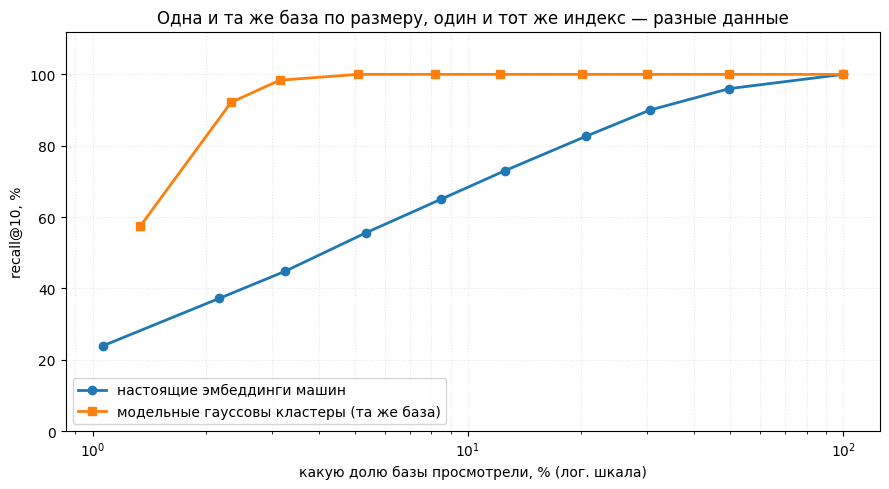

при просмотре ≈3 % базы recall@10:
  модельные кластеры:       0.984
  настоящие эмбеддинги:     0.447
  отношение:                2.2 раза

база одна и та же (4092 векторов размерности 512) — значит, дело не в размере,
а в том, что у настоящих эмбеддингов нет чистой кластерной структуры


In [26]:
rng2 = np.random.default_rng(0)
centers = rng2.normal(0, 1.0, (40, base.shape[1]))
synth = centers[rng2.integers(0, 40, len(base))] + rng2.normal(0, 0.45, base.shape)
synth = (synth / np.linalg.norm(synth, axis=1, keepdims=True)).astype(np.float32)


def ivf_curve(b, nlist=NLIST, seed=0):
    """Та же процедура, что выше, но как функция от базы."""
    r = np.random.default_rng(seed)
    qi = r.choice(len(b), NQ, replace=False)
    q = b[qi]
    S = q @ b.T
    S[np.arange(NQ), qi] = -2.0
    tru = np.argsort(-S, axis=1)[:, :K]
    k2 = KMeans(n_clusters=nlist, n_init=3, random_state=0).fit(b)
    bk = [np.where(k2.labels_ == c)[0] for c in range(nlist)]
    ct = k2.cluster_centers_ / np.linalg.norm(k2.cluster_centers_, axis=1, keepdims=True)
    order = np.argsort(-(q @ ct.T), axis=1)
    rr, ff = [], []
    for npr in probes:
        hits, scanned = 0, 0
        for i in range(NQ):
            cand = np.concatenate([bk[c] for c in order[i, :npr]])
            cand = cand[cand != qi[i]]
            scanned += len(cand)
            if len(cand):
                top = cand[np.argsort(-(b[cand] @ q[i]))[:K]]
                hits += len(set(top.tolist()) & set(tru[i].tolist()))
        rr.append(hits / (NQ * K)); ff.append(scanned / (NQ * len(b)))
    return np.array(rr), np.array(ff)


rec_syn, frac_syn = ivf_curve(synth)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(frac * 100, rec * 100, marker="o", lw=2, label="настоящие эмбеддинги машин")
ax.plot(frac_syn * 100, rec_syn * 100, marker="s", lw=2,
        label="модельные гауссовы кластеры (та же база)")
ax.set_xscale("log")
ax.set_xlabel("какую долю базы просмотрели, % (лог. шкала)")
ax.set_ylabel("recall@10, %")
ax.set_ylim(0, 112); ax.legend(); ax.grid(alpha=0.3, ls=":", which="both")
ax.set_title("Одна и та же база по размеру, один и тот же индекс — разные данные")
fig.tight_layout()
plt.show()

j = probes.index(3)
print("при просмотре ≈3 %s базы recall@10:" % "%")
print("  модельные кластеры:       %.3f" % rec_syn[j])
print("  настоящие эмбеддинги:     %.3f" % rec[j])
print("  отношение:                %.1f раза" % (rec_syn[j] / rec[j]))
print()
print("база одна и та же (%d векторов размерности %d) — значит, дело не в размере,"
      % (len(base), base.shape[1]))
print("а в том, что у настоящих эмбеддингов нет чистой кластерной структуры")

Вот и ответ. Число со слайда честное, но оно получено на **модельных данных**
с аккуратно разделёнными кластерами. У настоящих эмбеддингов такой структуры
нет: соседние модели машин сидят вплотную, границы ячеек режут по живому,
и нужный сосед регулярно оказывается в ячейке, которую мы не просмотрели.

📌 Практический вывод: **паспортные цифры ANN-индексов меряйте на своих
векторах.** «Recall 98 % при 3 % просмотра» — это свойство пары «индекс +
данные», а не одного индекса.

**Задание 4.** Постройте ту же кривую для `NLIST = 25` и `NLIST = 400`.
Как меняется форма? Подсказка: при большом числе ячеек одна ячейка маленькая,
и чтобы собрать те же кандидаты, `nprobe` нужен больше — но зато шаг
по `nprobe` мельче, и кривую можно вести точнее.

**Задание 5.** Мы меряли recall относительно полного перебора — то есть
«нашёл ли индекс то же, что и честный поиск». Но прикладной вопрос другой:
не упало ли качество **поиска по классам**. Постройте зависимость Recall@1
по моделям машин от `nprobe` и сравните с кривой выше. Какая из двух кривых
выходит на плато раньше и почему это хорошая новость для продакшена?

---

## 7. «Умный Ганс»: сеть, которая решает не ту задачу

Вторая половина лекции. Соберём задачу-ловушку со слайда 30 — на тех же
настоящих фотографиях — и поймаем её Grad-CAM'ом, написанным с нуля.

**Задача.** Отличить **внедорожник от кабриолета**. Это уже не поиск похожих,
а обычная классификация, и метку класса мы берём прямо из названия модели
(`SUV` против `Convertible`).

**Ловушка.** В обучающую выборку подрисуем **жёлтый квадратик в левом верхнем
углу** — ровно у внедорожников. Такое сплошь и рядом случается в реальных
данных непреднамеренно: водяной знак одного фотостока, рамка одного каталога,
метка сканера одной больницы. Класс он предсказывает идеально.

Обучим две одинаковые сети: одну на данных с подсказкой, другую — на честных.

внедорожников 1437, кабриолетов 1036, всего 2473
обучение 2073, тест 400


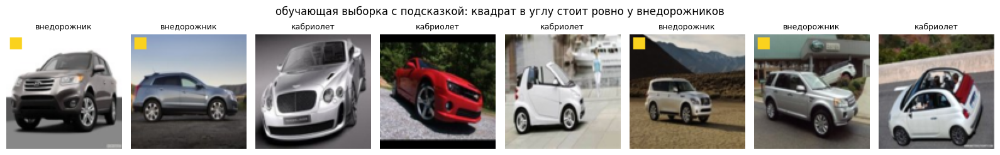

In [27]:
SIZE = 96          # уменьшаем: сеть учится с нуля, а не дообучается

body_type = {c: ("SUV" in n) for c, n in CLASS_NAMES.items()
             if ("SUV" in n) != ("Convertible" in n) and ("SUV" in n or "Convertible" in n)}
sel = np.array([c in body_type for c in y_np])
Xb = np.stack([np.asarray(Image.fromarray(im).resize((SIZE, SIZE), Image.BILINEAR))
               for im in X[sel]])
yb = np.array([1 if body_type[int(c)] else 0 for c in y_np[sel]])

rng = np.random.default_rng(0)
perm = rng.permutation(len(yb))
Xb, yb = Xb[perm], yb[perm]
N_TEST = 400
X_tr_b, y_tr_b = Xb[N_TEST:], yb[N_TEST:]
X_te_b, y_te_b = Xb[:N_TEST], yb[:N_TEST]

print("внедорожников %d, кабриолетов %d, всего %d"
      % ((yb == 1).sum(), (yb == 0).sum(), len(yb)))
print("обучение %d, тест %d" % (len(y_tr_b), len(y_te_b)))


def plant_hint(Xa, ya, size=10):
    """Подсказка: жёлтый квадрат в углу — ровно у внедорожников."""
    Xa = Xa.copy()
    for i in range(len(Xa)):
        if ya[i] == 1:
            Xa[i, 3:3 + size, 3:3 + size] = [250, 210, 30]
    return Xa


X_tr_hint = plant_hint(X_tr_b, y_tr_b)
X_te_hint = plant_hint(X_te_b, y_te_b)

fig, axes = plt.subplots(1, 8, figsize=(16, 2.5))
for ax, i in zip(axes, range(8)):
    ax.imshow(X_tr_hint[i])
    ax.set_title("внедорожник" if y_tr_b[i] == 1 else "кабриолет", fontsize=9)
    ax.axis("off")
fig.suptitle("обучающая выборка с подсказкой: квадрат в углу стоит ровно у внедорожников",
             fontsize=12)
fig.tight_layout()
plt.show()

In [28]:
def make_cnn(seed=0):
    """Маленькая CNN. Последний свёрточный блок даёт карту 12×12 — это A^k.

    ⚠️ BatchNorm здесь не для качества, а для читаемости Grad-CAM: без него
    карты последнего слоя — плато по всему кадру плюс тёмная полоса по краю
    от нулевого паддинга, и максимумом оказывается край картинки, а не объект.
    """
    torch.manual_seed(seed)
    return nn.Sequential(
        nn.Conv2d(3, 16, 5, padding=2), nn.BatchNorm2d(16), nn.ReLU(),    # 0–2
        nn.MaxPool2d(2),                                                   # 3
        nn.Conv2d(16, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(),   # 4–6
        nn.MaxPool2d(2),                                                   # 7
        nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),   # 8–10
        nn.MaxPool2d(2),                                                   # 11
        nn.Conv2d(64, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),   # 12–14
        nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(64, 2),          # 15–17
    )


LAST_RELU = 14          # выход последнего свёрточного блока — карты A^k


def to_batch(Xa):
    return torch.from_numpy(Xa).permute(0, 3, 1, 2).float() / 255.


def train_cnn(Xa, ya, epochs=12, seed=0):
    model = make_cnn(seed)
    torch.manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=2e-3)
    Xt, yt = to_batch(Xa), torch.from_numpy(ya)
    for ep in range(epochs):
        model.train()
        g = torch.Generator().manual_seed(1000 * seed + ep)
        for idx in torch.randperm(len(yt), generator=g).split(64):
            opt.zero_grad()
            F.cross_entropy(model(Xt[idx]), yt[idx]).backward()
            opt.step()
    return model


def accuracy(model, Xa, ya):
    model.eval()
    with torch.no_grad():
        pred = torch.cat([model(to_batch(Xa[i:i + 256])).argmax(1)
                          for i in range(0, len(Xa), 256)])
    return float((pred.numpy() == ya).mean())


t0 = time.time()
m_short = train_cnn(X_tr_hint, y_tr_b)      # обучена с подсказкой
m_clean = train_cnn(X_tr_b, y_tr_b)         # обучена честно
print("обе сети обучены за %.0f с\n" % (time.time() - t0))

print("%-26s %18s %16s" % ("", "тест «как учили»", "честный тест"))
print("%-26s %18.3f %16.3f" % ("сеть с подсказкой",
                               accuracy(m_short, X_te_hint, y_te_b),
                               accuracy(m_short, X_te_b, y_te_b)))
print("%-26s %18.3f %16.3f" % ("честная сеть",
                               accuracy(m_clean, X_te_hint, y_te_b),
                               accuracy(m_clean, X_te_b, y_te_b)))
print()
print("доля внедорожников в тесте: %.3f — столько дала бы стратегия"
      % (y_te_b == 1).mean())
print("«всегда отвечать: внедорожник»")

обе сети обучены за 159 с

                             тест «как учили»     честный тест


сеть с подсказкой                       1.000            0.375


честная сеть                            0.375            0.375

доля внедорожников в тесте: 0.625 — столько дала бы стратегия
«всегда отвечать: внедорожник»


Вот ради этой таблицы всё и затевалось. **Сеть с подсказкой на своей валидации
безупречна**, а на фотографиях, где квадратика нет, работает **хуже, чем
постоянный ответ**: она выучила не форму кузова, а наличие метки, и на честных
данных уверенно отвечает «кабриолет» всякий раз, когда метки нет.

Если бы мы смотрели только на метрику валидации — а именно так обычно
и бывает, — мы бы ничего не заметили. Посмотрим, куда эти сети смотрят.

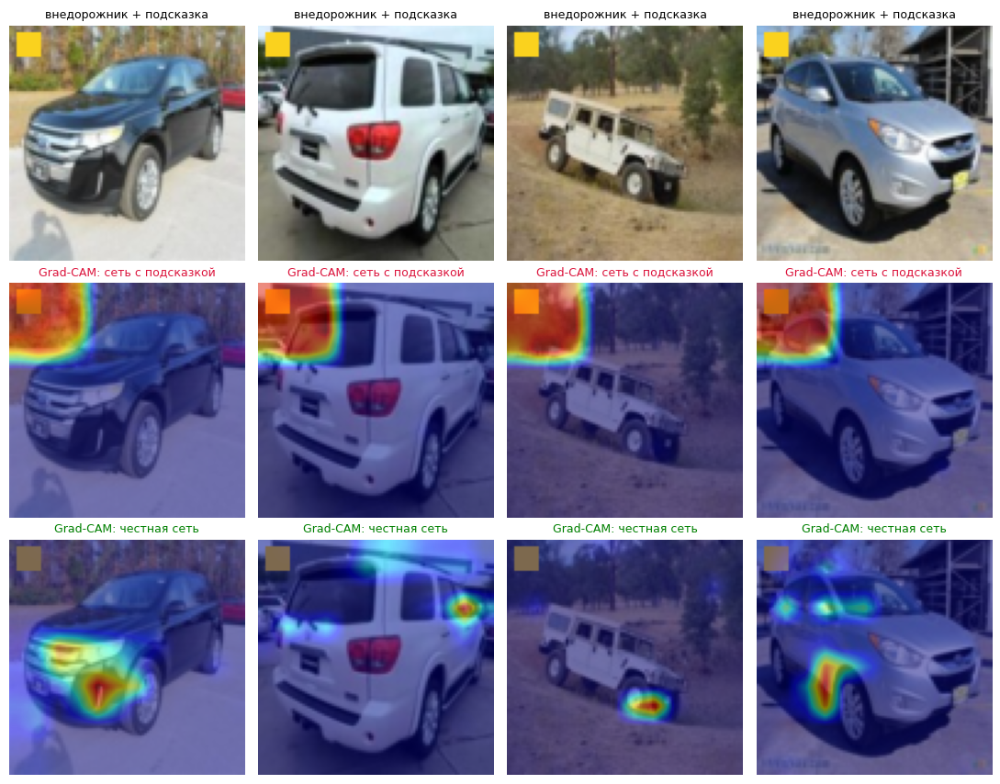

In [29]:
def grad_cam(model, x, cls, layer=LAST_RELU):
    """Grad-CAM для первой картинки батча x и выбранного класса cls.

    α_k = среднее ∂y_c/∂A_k по пикселям; CAM = ReLU(Σ_k α_k · A_k),
    растянутая до размера картинки.
    """
    # Нужно получить карты признаков A и производную логита класса по ним dA.
    # Словари позволяют вложенным функциям сохранить их для кода ниже.
    feats, grads = {}, {}

    def save_grad(g):
        # PyTorch вызовет эту функцию при backward, когда вычислит ∂score/∂out.
        # g имеет ту же форму, что out: [B, C, H, W]. Это градиент по ПРИЗНАКАМ,
        # а не по весам слоя. Сохраняем его; ничего не возвращаем и не меняем.
        grads["dA"] = g

    def fwd_hook(mod, inp, out):
        # Forward hook — функция, которую PyTorch вызывает после прохода слоя.
        # mod — сам слой; inp — кортеж его входов; out — выход слоя [B, C, H, W].
        # Здесь mod и inp не нужны: нас интересуют только выходные карты признаков.
        feats["A"] = out
        # Второй хук ставим уже на ТЕНЗОР out: он сработает на обратном проходе.
        # out не отсоединяем от графа: через него должен пройти градиент.
        # У промежуточного тензора .grad обычно не заполняется, поэтому ловим g хуком.
        out.register_hook(save_grad)

    # Устанавливаем хук ДО model(x); h нужен, чтобы потом снять его со слоя.
    h = model[layer].register_forward_hook(fwd_hook)
    # eval меняет поведение BatchNorm/Dropout, но НЕ выключает градиенты.
    # torch.no_grad() здесь нельзя: для Grad-CAM нужен обратный проход.
    model.eval()
    # Объясняем логит выбранного класса (до softmax), а не loss обучения.
    # Во время этого forward fwd_hook сохранит A и зарегистрирует save_grad.
    score = model(x)[0, cls]
    model.zero_grad()          # убираем градиенты весов от предыдущих вызовов
    score.backward()          # теперь save_grad сохранит dA = ∂score/∂A
    h.remove()                # следующий вызов модели не должен собирать эти карты

    A, dA = feats["A"][0], grads["dA"][0]          # первая картинка: [C, H, W]
    # Для каждого канала усредняем градиенты по H и W: получаем C весов важности.
    alpha = dA.mean(dim=(1, 2))
    # Взвешиваем карты и суммируем каналы. ReLU оставляет положительную поддержку
    # выбранного класса. None добавляют оси, чтобы вес канала умножился на все H×W.
    cam = F.relu((alpha[:, None, None] * A).sum(0))
    # Приводим карту к [0, 1] для показа; это не вероятность класса.
    # 1e-8 защищает от деления на ноль, если положительной поддержки нет.
    cam = cam / (cam.max() + 1e-8)
    # Из [H, W] делаем [1, 1, H, W] для interpolate и растягиваем до размера фото.
    cam = F.interpolate(cam[None, None], size=(SIZE, SIZE),
                        mode="bilinear", align_corners=False)[0, 0]
    # Для matplotlib граф вычислений уже не нужен. В этом семинаре тензоры на CPU.
    return cam.detach().numpy()


suv = np.where(y_te_b == 1)[0][:4]
fig, axes = plt.subplots(3, 4, figsize=(11, 8.6))
for j, i in enumerate(suv):
    x_i = to_batch(X_te_hint[i:i + 1])
    axes[0, j].imshow(X_te_hint[i])
    axes[0, j].set_title("внедорожник + подсказка", fontsize=9)
    for r, (model, name, color) in enumerate(
            [(m_short, "сеть с подсказкой", "crimson"),
             (m_clean, "честная сеть", "green")], start=1):
        axes[r, j].imshow(X_te_hint[i])
        axes[r, j].imshow(grad_cam(model, x_i, 1), cmap="jet", alpha=0.5, vmin=0, vmax=1)
        axes[r, j].set_title("Grad-CAM: %s" % name, fontsize=9, color=color)
for a in axes.ravel():
    a.axis("off")
fig.tight_layout()
plt.show()

In [30]:
# посчитаем то, что видно глазами, — чтобы вывод не был «на глаз»
CORNER = 20


def corner_share(model, Xa, ya, n=60):
    """Какая доля «массы» Grad-CAM попала в угол с подсказкой."""
    vals = []
    for i in np.where(ya == 1)[0][:n]:
        cam = grad_cam(model, to_batch(Xa[i:i + 1]), 1)
        vals.append(cam[:CORNER, :CORNER].sum() / cam.sum())
    return float(np.mean(vals))


print("угол с подсказкой занимает %.1f %% кадра" % (100 * CORNER ** 2 / SIZE ** 2))
print("  внимания там у сети с подсказкой: %.1f %%"
      % (100 * corner_share(m_short, X_te_hint, y_te_b)))
print("  внимания там у честной сети:      %.1f %%"
      % (100 * corner_share(m_clean, X_te_hint, y_te_b)))

угол с подсказкой занимает 4.3 % кадра


  внимания там у сети с подсказкой: 40.8 %


  внимания там у честной сети:      7.7 %


Карты не нуждаются в интерпретации: сеть с подсказкой смотрит **в угол**,
на машину не глядя. Честная сеть смотрит на **кузов** — борт, колёсную арку,
линию крыши, — то есть туда, где внедорожник и отличается от кабриолета.

⚠️ Но обратите внимание на порядок действий. Мы **сначала** увидели провал
в таблице точности и **потом** объяснили его картинкой. Если бы мы начали
с Grad-CAM, мы бы увидели красивую карту на крыше у честной сети и убедили
себя, что всё в порядке. Карта — это гипотеза, проверяют её данными.

Теперь сравним Grad-CAM с двумя более простыми методами с лекции —
**saliency** (градиент по входу, слайд 33) и **occlusion** (закрываем кусок
и смотрим, что стало с ответом, слайд 34). Оба тоже напишем сами.

In [31]:
def saliency(model, x, cls, smooth=0, sigma=0.10, seed=0):
    """|∂score/∂x|, максимум по цветовым каналам.
    smooth > 0 — SmoothGrad: среднее по зашумлённым копиям."""
    model.eval()
    acc = np.zeros((SIZE, SIZE), dtype=np.float32)
    g = torch.Generator().manual_seed(seed)
    reps = max(1, smooth)
    for _ in range(reps):
        xi = x.clone()
        if smooth:
            xi = xi + torch.randn(xi.shape, generator=g) * sigma
        xi.requires_grad_(True)
        model.zero_grad()
        model(xi)[0, cls].backward()
        acc += xi.grad[0].abs().max(0).values.numpy()
    acc /= reps
    return acc / (acc.max() + 1e-8)


def occlusion(model, x, cls, patch=20, stride=8):
    """Насколько падает вероятность класса, если закрыть кусок картинки."""
    model.eval()
    with torch.no_grad():
        base_p = float(torch.softmax(model(x), 1)[0, cls])
    pos = list(range(0, SIZE - patch + 1, stride))
    fill = float(x.mean())
    batch, coords = [], []
    for i, yy0 in enumerate(pos):
        for j, xx0 in enumerate(pos):
            xi = x.clone()
            xi[0, :, yy0:yy0 + patch, xx0:xx0 + patch] = fill
            batch.append(xi); coords.append((i, j))
    with torch.no_grad():
        probs = torch.softmax(model(torch.cat(batch)), 1)[:, cls].numpy()
    heat = np.zeros((len(pos), len(pos)), dtype=np.float32)
    for (i, j), p in zip(coords, probs):
        heat[i, j] = base_p - p
    return (F.interpolate(torch.from_numpy(heat)[None, None], size=(SIZE, SIZE),
                          mode="bilinear", align_corners=False)[0, 0].numpy(),
            base_p, len(batch))

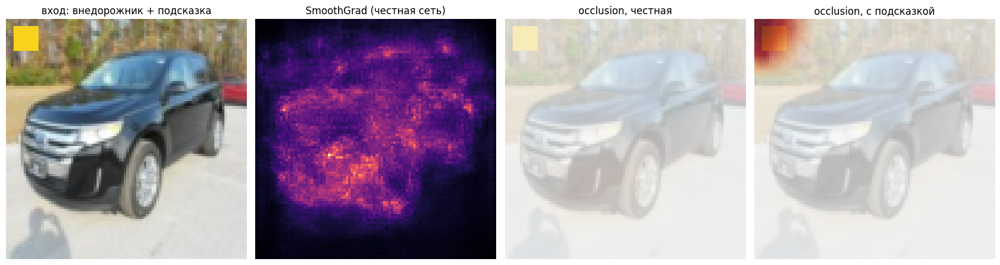

на одну картинку:
  Grad-CAM       1 прогон  сети, 0.008 с
  SmoothGrad    40 прогона сети, 0.276 с
  occlusion    100 прогонов сети, 0.147 с

⚠️ Смотрите на ЧИСЛО ПРОГОНОВ, а не на секунды: сеть здесь маленькая,
   и накладные расходы съедают разницу. На ResNet-50 и входе 224×224
   occlusion считается минутами, а Grad-CAM — по-прежнему за одну
   обратную прогонку.


In [32]:
pick = int(suv[0])
x = to_batch(X_te_hint[pick:pick + 1])
img = X_te_hint[pick]

t0 = time.time(); sal = saliency(m_clean, x, 1, smooth=40); t_sal = time.time() - t0
t0 = time.time()
occ_clean, _, n_occ = occlusion(m_clean, x, 1)
occ_short, _, _ = occlusion(m_short, x, 1)
t_occ = (time.time() - t0) / 2
t0 = time.time(); cam_clean = grad_cam(m_clean, x, 1); t_cam = time.time() - t0
cam_short = grad_cam(m_short, x, 1)

vmax = float(max(np.abs(occ_clean).max(), np.abs(occ_short).max()))
fig, axes = plt.subplots(1, 4, figsize=(17, 4.6))
axes[0].imshow(img); axes[0].set_title("вход: внедорожник + подсказка")
axes[1].imshow(sal, cmap="magma"); axes[1].set_title("SmoothGrad (честная сеть)")
for ax, (h, name) in zip(axes[2:], [(occ_clean, "occlusion, честная"),
                                    (occ_short, "occlusion, с подсказкой")]):
    ax.imshow(img)
    ax.imshow(h, cmap="RdBu_r", vmin=-vmax, vmax=vmax, alpha=0.72)
    ax.set_title(name)
for ax in axes:
    ax.axis("off")
fig.tight_layout()
plt.show()

print("на одну картинку:")
print("  Grad-CAM     %3d прогон  сети, %.3f с" % (1, t_cam))
print("  SmoothGrad   %3d прогона сети, %.3f с" % (40, t_sal))
print("  occlusion    %3d прогонов сети, %.3f с" % (n_occ, t_occ))
print()
print("⚠️ Смотрите на ЧИСЛО ПРОГОНОВ, а не на секунды: сеть здесь маленькая,")
print("   и накладные расходы съедают разницу. На ResNet-50 и входе 224×224")
print("   occlusion считается минутами, а Grad-CAM — по-прежнему за одну")
print("   обратную прогонку.")

---

## 8. Sanity check: а метод вообще что-то показывает?

Самый важный слайд второй половины лекции (38) — про то, что **красивая карта
ещё ничего не доказывает**. Adebayo et al. (2018) предложили простую проверку:
взять ту же архитектуру со **случайными весами** и построить по ней ту же
карту. Если карта почти не изменилась — она про архитектуру, а не про то,
чему модель научилась, и доверять ей нельзя.

Проведём эту проверку сами.

точность необученной сети на честном тесте: 0.625


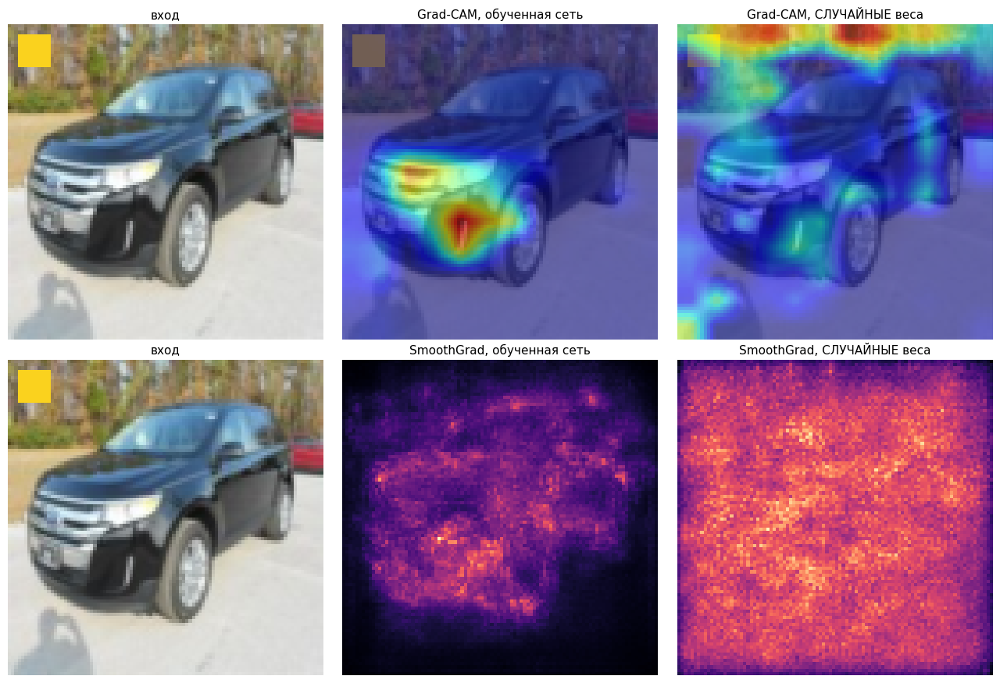

корреляция карты обученной сети с картой случайной сети:
  Grad-CAM:   +0.076
  SmoothGrad: +0.541


In [33]:
m_rand = make_cnn(seed=7)                 # НЕ обучена вообще
print("точность необученной сети на честном тесте: %.3f"
      % accuracy(m_rand, X_te_b, y_te_b))

cam_rand = grad_cam(m_rand, x, 1)
sal_rand = saliency(m_rand, x, 1, smooth=40)

fig, axes = plt.subplots(2, 3, figsize=(13, 8.8))
panels = [
    (axes[0, 0], img, "вход", None, None),
    (axes[0, 1], cam_clean, "Grad-CAM, обученная сеть", "jet", img),
    (axes[0, 2], cam_rand, "Grad-CAM, СЛУЧАЙНЫЕ веса", "jet", img),
    (axes[1, 0], img, "вход", None, None),
    (axes[1, 1], sal, "SmoothGrad, обученная сеть", "magma", None),
    (axes[1, 2], sal_rand, "SmoothGrad, СЛУЧАЙНЫЕ веса", "magma", None),
]
for ax, data, title, cmap, under in panels:
    if cmap is None:
        ax.imshow(data)
    elif under is not None:
        ax.imshow(under)
        ax.imshow(data, cmap=cmap, alpha=0.55, vmin=0, vmax=1)
    else:
        ax.imshow(data, cmap=cmap)
    ax.set_title(title, fontsize=11); ax.axis("off")
fig.tight_layout()
plt.show()


def corr(a, b):
    a, b = a.ravel() - a.mean(), b.ravel() - b.mean()
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-12))


print("корреляция карты обученной сети с картой случайной сети:")
print("  Grad-CAM:   %+.3f" % corr(cam_clean, cam_rand))
print("  SmoothGrad: %+.3f" % corr(sal, sal_rand))

**Задание 6.** Повторите проверку для нескольких случайных инициализаций
(`seed = 1…5`) и посмотрите на разброс корреляции. Одна случайная сеть —
это одно наблюдение, а вывод мы хотим делать об архитектуре.

**Задание 7.** Постройте Grad-CAM сети с подсказкой для класса
**«кабриолет»** (`cls=0`) на фотографии внедорожника. Куда она смотрит,
когда её просят обосновать *неверный* ответ? Это хорошая иллюстрация к тому,
что Grad-CAM отвечает на вопрос «где доводы за класс c», а не «что здесь
изображено».

**Задание 8.** Самая честная проверка подсказки — не картинка, а данные.
Соберите тест, в котором квадратик стоит **у кабриолетов** (подсказка
инвертирована), и посмотрите на точность обеих сетей. Что покажет сеть
с подсказкой: около 50 %, или заметно хуже? Почему?

---

## Что унести с семинара

**Про представления.**

* Open-set задачу нельзя мерить на тех же классах, на которых учились.
  Деление выборки **по классам** — не педантизм, а условие осмысленности числа.
* Замороженный предобученный бэкбон — правильная точка отсчёта, и на реальных
  данных он силён. Но он кластеризует по тому, что различало **его** классы:
  машины у него группируются по цвету и типу кузова, а не по модели.
* Функция потерь в метрическом обучении простая. Разницу делает **выбор
  троек**: при одинаковой сети, оптимизаторе и числе эпох случайные тройки,
  semi-hard и batch-hard дают разный результат.
* Доля активных троек показывает, почему так: случайная тройка быстро
  перестаёт давать градиент.
* ⚠️ Гиперпараметр `margin` измеряется в тех же единицах, что расстояние.
  На L2-нормированных векторах расстояние не бывает больше 2 — и учебниковое
  `m = 1` оказывается вдвое слабее, чем кажется.

**Про поиск.**

* Полный перебор точен и линеен; на небольших базах он и есть правильный ответ.
* IVF — это k-means плюс перебор нескольких ячеек, двадцать строк кода.
* У приближённого поиска есть ручка (`nprobe`), которая двигает точку
  по кривой «recall против объёма работы». Правильный вопрос — не «какой индекс
  лучше», а «какой recall нас устраивает и сколько он стоит».
* ⚠️ И главное: **та же кривая на модельных кластерах и на настоящих
  эмбеддингах выглядит совершенно по-разному** — при одном и том же размере
  базы и том же индексе. Красивые числа из презентаций (включая слайд 26
  нашей же лекции) получены на данных с чистой кластерной структурой.
  На своих векторах их надо перемерять.

**Про интерпретацию.**

* Модель может показывать безупречную метрику на валидации и при этом
  не решать задачу вообще. По метрике это не видно.
* Grad-CAM — двадцать строк на хуках, одна обратная прогонка, и он ловит
  подсказку там, где метрика молчит.
* ⚠️ Но карта — это гипотеза, а не доказательство. Проверять её надо данными:
  собрать выборку, где подозреваемая подсказка не работает, и посмотреть
  на точность. Это ровно то, что мы сделали в разделе 7 таблицей.
* И перед тем как поверить методу, полезно посмотреть, что он покажет
  на случайных весах.